# 08 Report maps with reliability marked

Redraws the climatology, weighting and uncertainty maps from 03 and 04 with one rule: every cell with data is shown, and reliability from 06 is marked (hatched = unreliable, outlined = reliable or weighting-sensitive). Reads saved outputs only; writes figures to `08_maps_with_reliability/`.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

sys.path.insert(0, "../src")   # shared grid + map helpers live in src/grid.py
from grid import (LON_MIN, LON_MAX, LAT_MIN, LAT_MAX, RES, lon_edges, lat_edges, proj, style_map)
from grid import nx as NX, ny as NY

In [2]:
DATA_DIR = Path("../data")
FIG_DIR  = Path("../figures")
FIG_OUT  = FIG_DIR / "08_maps_with_reliability"
DIR_03   = DATA_DIR / "03_aggregation_and_means"      # 03_summary (colour ranges of the 03 maps)
DIR_06   = DATA_DIR / "06_reliability"                # product tables, 06_summary
OUT_DIR  = DATA_DIR / "08_maps_with_reliability"      # 08_summary (colour caps, counts)
FIG_OUT.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Settings ---
s03 = json.loads((DIR_03 / "03_summary.json").read_text())
SPEED_VMAX_PCT = 95                                       # climatology colour cap: this percentile of cell speeds (viridis, from 0)
SST_RANGE_C = s03["sst_range_c"]                          # 03 climatology: RdYlBu_r over the SST range
WEIGHT_VMAX_CMPS = s03["weighting_map_vmax_p95_ms"] * 100 # 03 weighting map: Reds, capped at its 95th percentile
U95_VMAX_CMPS = 20                                        # as in 04
SST_HW_VMAX_C = 1.0                                       # as in 04
ARROW_SCALE = 800                                         # 03 used scale=8 with m/s; here cm/s

HATCH = "////"                 # unreliable cells
HATCH_COLOR = "0.6"            # mid grey (visible on pale cells too)
OUTLINE_COLOR = "k"
OUTLINE_LW = 1.0

vel = pd.read_parquet(DIR_06 / "product_velocity_1deg.parquet")   # one row per cell, grid order
sst = pd.read_parquet(DIR_06 / "product_sst_1deg.parquet")
s06 = json.loads((DIR_06 / "06_summary.json").read_text())
assert len(vel) == len(sst) == NY * NX
assert (vel[["iy", "ix"]].to_numpy() == sst[["iy", "ix"]].to_numpy()).all()

counts = {}   # cells drawn / hatched / outlined per figure, checked against 06 at the end
summary = {}

In [3]:
def to_grid(values, show):
    """Per-cell column → (NY, NX) array, NaN outside `show`."""
    return np.where(np.asarray(show), np.asarray(values, dtype=float), np.nan).reshape(NY, NX)


def hatch_cells(ax, table, mask):
    """Light grey hatching over the given cells (marks 'unreliable')."""
    for iy, ix in table.loc[np.asarray(mask), ["iy", "ix"]].to_numpy():
        ax.add_patch(Rectangle((lon_edges[ix], lat_edges[iy]), RES, RES, fill=False, hatch=HATCH,
                               edgecolor=HATCH_COLOR, lw=0, transform=proj, zorder=1.5))
    return int(np.asarray(mask).sum())


def outline_cells(ax, table, mask):
    """Black outline around the given cells."""
    for iy, ix in table.loc[np.asarray(mask), ["iy", "ix"]].to_numpy():
        ax.add_patch(Rectangle((lon_edges[ix], lat_edges[iy]), RES, RES, fill=False,
                               edgecolor=OUTLINE_COLOR, lw=OUTLINE_LW, transform=proj, zorder=1.6))
    return int(np.asarray(mask).sum())


def legend_patches(ax, hatched=None, outlined=None):
    """Small legend: hatched and/or outlined patch, labelled."""
    handles = []
    if hatched:
        handles.append(Patch(facecolor="white", edgecolor=HATCH_COLOR, hatch=HATCH, label=hatched))
    if outlined:
        handles.append(Patch(facecolor="none", edgecolor=OUTLINE_COLOR, lw=OUTLINE_LW, label=outlined))
    ax.legend(handles=handles, loc="lower right", fontsize=8, framealpha=0.9).set_zorder(5)

## Mean current and SST, reliability marked

speed colour cap (95th percentile of 595 cells): 45.93 cm/s


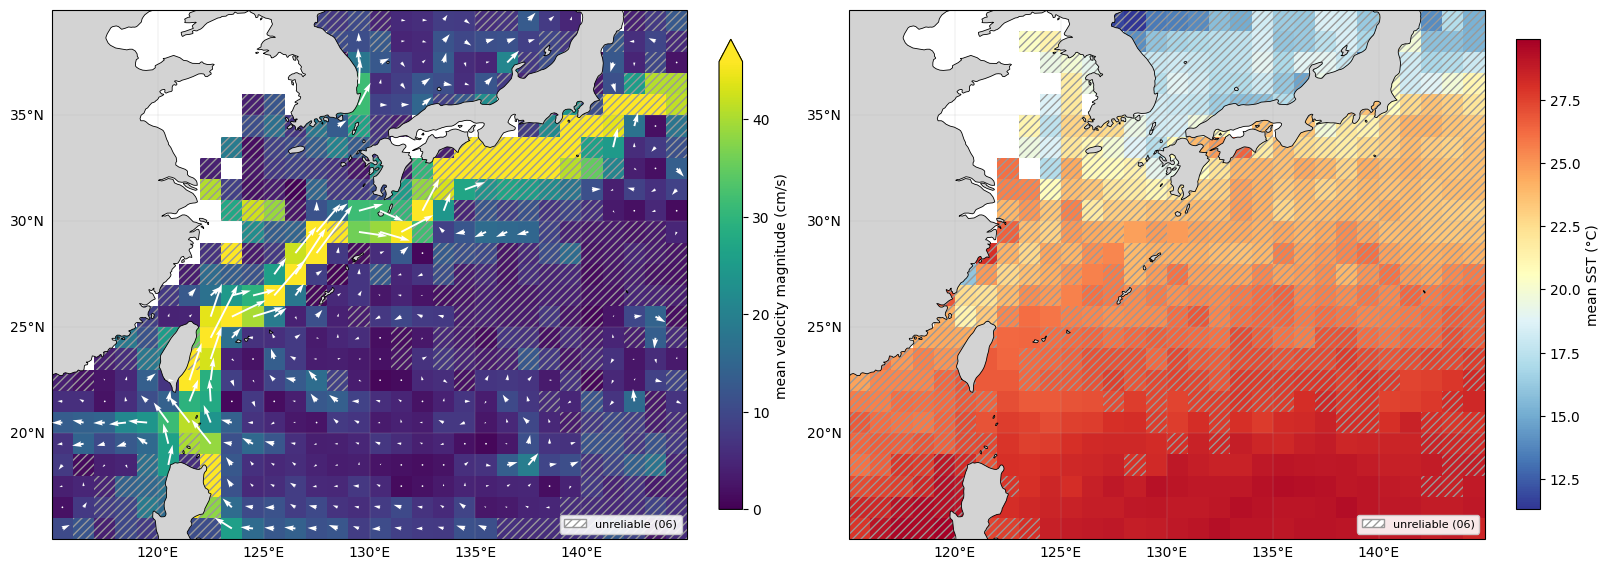

{'drawn': 595, 'arrows': 310, 'hatched': 285} {'drawn': 618, 'hatched': 471}


In [4]:
has_vel = vel["n_drifters"] > 0
has_sst = sst["n_drifters"] > 0
rel_v = vel["reliable"].astype(bool)
rel_s = sst["reliable"].astype(bool)

# Colour cap for panel (a): 95th percentile of the mean-vector speed over cells with velocity data
speed_vmax = float(np.percentile(vel.loc[has_vel, "mean_vector_speed_cmps"], SPEED_VMAX_PCT))
summary["climatology_speed_vmax_cmps"] = round(speed_vmax, 2)
summary["climatology_speed_vmax_percentile"] = SPEED_VMAX_PCT
print(f"speed colour cap ({SPEED_VMAX_PCT}th percentile of {has_vel.sum()} cells): {speed_vmax:.2f} cm/s")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), layout="constrained", subplot_kw={"projection": proj})

# (a) Mean current: colour = speed of the mean vector, arrows only where reliable
ax = axes[0]
im = ax.pcolormesh(lon_edges, lat_edges, to_grid(vel["mean_vector_speed_cmps"], has_vel),
                   cmap="viridis", vmin=0, vmax=speed_vmax, transform=proj)
r = vel[rel_v]
ax.quiver(r["lon_center"], r["lat_center"], r["mean_ve_cmps"], r["mean_vn_cmps"],
          scale=ARROW_SCALE, width=0.003, color="white", transform=proj, zorder=4)
n_hatch = hatch_cells(ax, vel, has_vel & ~rel_v)
style_map(ax)
legend_patches(ax, hatched="unreliable (06)")
fig.colorbar(im, ax=ax, shrink=0.8, extend="max", label="mean velocity magnitude (cm/s)")
counts["climatology_velocity"] = {"drawn": int(has_vel.sum()), "arrows": int(len(r)), "hatched": n_hatch}

# (b) Mean SST
ax = axes[1]
im = ax.pcolormesh(lon_edges, lat_edges, to_grid(sst["mean_sst_c"], has_sst),
                   cmap="RdYlBu_r", vmin=SST_RANGE_C[0], vmax=SST_RANGE_C[1], transform=proj)
n_hatch = hatch_cells(ax, sst, has_sst & ~rel_s)
style_map(ax)
legend_patches(ax, hatched="unreliable (06)")
fig.colorbar(im, ax=ax, shrink=0.8, label="mean SST (°C)")
counts["climatology_sst"] = {"drawn": int(has_sst.sum()), "hatched": n_hatch}

fig.savefig(FIG_OUT / "climatology_vel_sst_reliability.png", dpi=300, bbox_inches="tight")
plt.show()
print(counts["climatology_velocity"], counts["climatology_sst"])

## Weighting sensitivity, reliability marked

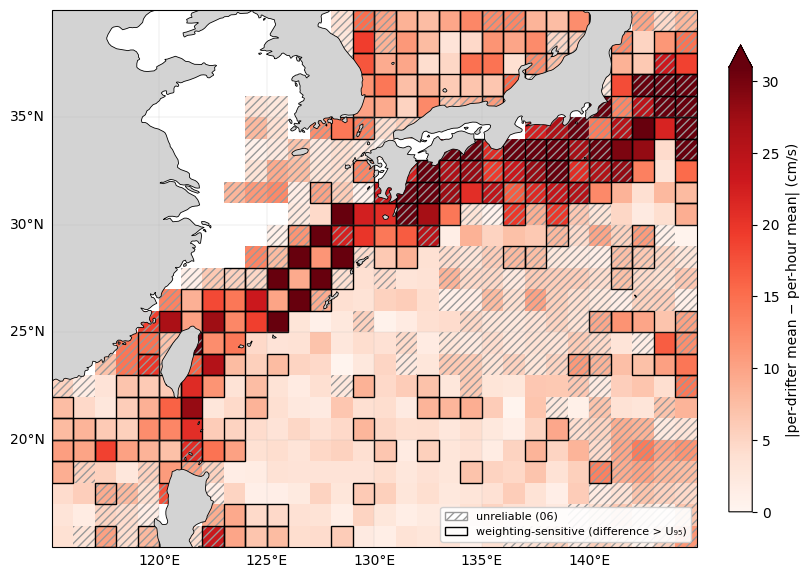

{'drawn': 577, 'hatched': 267, 'outlined': 221}


In [5]:
ci_v = vel["bootstrap_vector_radius95_cmps"].notna()          # cells with a bootstrap interval
sens = vel["weighting_sensitive"].fillna(False).astype(bool)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained", subplot_kw={"projection": proj})
im = ax.pcolormesh(lon_edges, lat_edges, to_grid(vel["weighting_diff_cmps"], ci_v),
                   cmap="Reds", vmin=0, vmax=WEIGHT_VMAX_CMPS, transform=proj)
n_hatch = hatch_cells(ax, vel, ci_v & ~rel_v)
n_out = outline_cells(ax, vel, ci_v & sens)
style_map(ax)
legend_patches(ax, hatched="unreliable (06)", outlined="weighting-sensitive (difference > U₉₅)")
fig.colorbar(im, ax=ax, shrink=0.8, extend="max", label="|per-drifter mean − per-hour mean| (cm/s)")
fig.savefig(FIG_OUT / "weighting_sensitivity_reliability.png", dpi=300, bbox_inches="tight")
plt.show()
counts["weighting"] = {"drawn": int(ci_v.sum()), "hatched": n_hatch, "outlined": n_out}
print(counts["weighting"])

## Uncertainty of the mean current (U95), reliable cells outlined

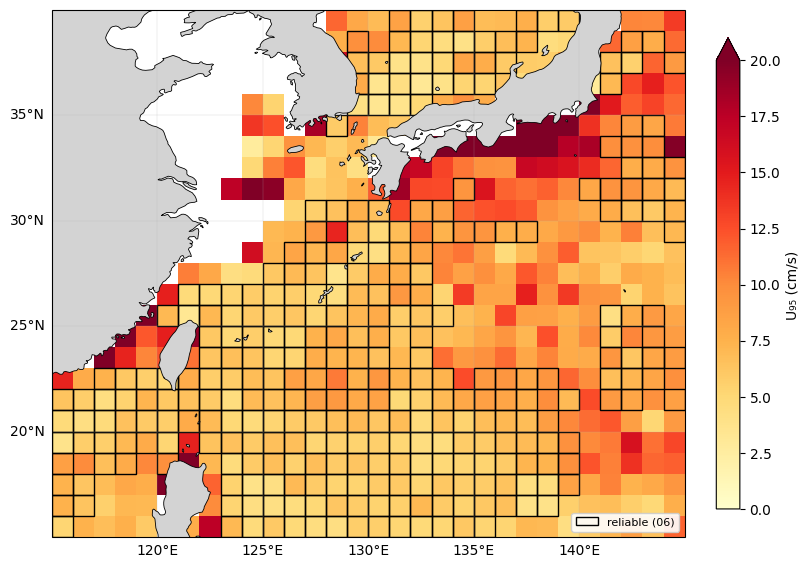

{'drawn': 577, 'outlined': 310}


In [6]:
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained", subplot_kw={"projection": proj})
im = ax.pcolormesh(lon_edges, lat_edges, to_grid(vel["bootstrap_vector_radius95_cmps"], ci_v),
                   cmap="YlOrRd", vmin=0, vmax=U95_VMAX_CMPS, transform=proj)
n_out = outline_cells(ax, vel, ci_v & rel_v)
style_map(ax)
legend_patches(ax, outlined="reliable (06)")
fig.colorbar(im, ax=ax, shrink=0.8, extend="max", label="U₉₅ (cm/s)")
fig.savefig(FIG_OUT / "U95_map_reliability.png", dpi=300, bbox_inches="tight")
plt.show()
counts["U95"] = {"drawn": int(ci_v.sum()), "outlined": n_out}
print(counts["U95"])

## Uncertainty of mean SST, reliable cells outlined

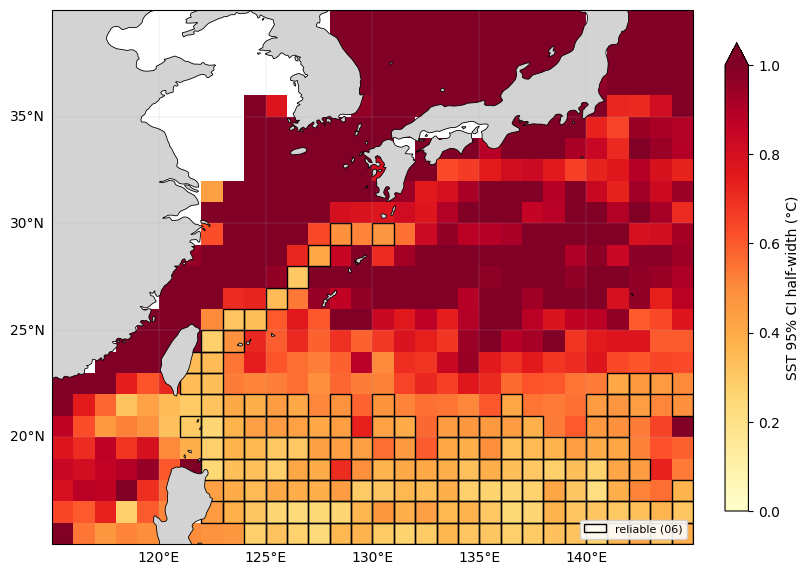

{'drawn': 598, 'outlined': 147}


In [7]:
ci_s = sst["sst_ci_halfwidth_c"].notna()

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained", subplot_kw={"projection": proj})
im = ax.pcolormesh(lon_edges, lat_edges, to_grid(sst["sst_ci_halfwidth_c"], ci_s),
                   cmap="YlOrRd", vmin=0, vmax=SST_HW_VMAX_C, transform=proj)
n_out = outline_cells(ax, sst, ci_s & rel_s)
style_map(ax)
legend_patches(ax, outlined="reliable (06)")
fig.colorbar(im, ax=ax, shrink=0.8, extend="max", label="SST 95% CI half-width (°C)")
fig.savefig(FIG_OUT / "sst_halfwidth_map_reliability.png", dpi=300, bbox_inches="tight")
plt.show()
counts["sst_halfwidth"] = {"drawn": int(ci_s.sum()), "outlined": n_out}
print(counts["sst_halfwidth"])

## Checks against 06

In [8]:
v6, ws6 = s06["velocity"], s06["weighting_sensitive"]["all_ci_cells"]
n_sensitive_06 = ws6["n_sensitive"]                             # stored count from 06
checks = {
    "velocity cells with data":        (counts["climatology_velocity"]["drawn"], v6["cells_with_data"]),
    "velocity arrows = reliable":      (counts["climatology_velocity"]["arrows"], v6["reliable"]),
    "velocity hatched = data − reliable": (counts["climatology_velocity"]["hatched"], v6["cells_with_data"] - v6["reliable"]),
    "SST cells with data":             (counts["climatology_sst"]["drawn"], s06["sst"]["cells_with_data"]),
    "SST hatched = data − reliable":   (counts["climatology_sst"]["hatched"], s06["sst"]["cells_with_data"] - s06["sst"]["reliable"]),
    "weighting cells = with interval": (counts["weighting"]["drawn"], ws6["n_cells"]),
    "weighting outlined = sensitive":  (counts["weighting"]["outlined"], n_sensitive_06),
    "weighting outlined & reliable":   (int((ci_v & sens & rel_v).sum()),
                                        s06["weighting_sensitive"]["reliable"]["n_sensitive"]),
    "weighting hatched = interval − reliable": (counts["weighting"]["hatched"], ws6["n_cells"] - v6["reliable"]),
    "U95 cells = with interval":       (counts["U95"]["drawn"], ws6["n_cells"]),
    "U95 outlined = reliable":         (counts["U95"]["outlined"], v6["reliable"]),
    "SST half-width outlined = reliable": (counts["sst_halfwidth"]["outlined"], s06["sst"]["reliable"]),
}
for name, (got, expected) in checks.items():
    print(f"{'ok ' if got == expected else 'MISMATCH'} {name}: {got} (06: {expected})")
assert all(g == e for g, e in checks.values())
summary["counts"] = counts
(OUT_DIR / "08_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

ok  velocity cells with data: 595 (06: 595)
ok  velocity arrows = reliable: 310 (06: 310)
ok  velocity hatched = data − reliable: 285 (06: 285)
ok  SST cells with data: 618 (06: 618)
ok  SST hatched = data − reliable: 471 (06: 471)
ok  weighting cells = with interval: 577 (06: 577)
ok  weighting outlined = sensitive: 221 (06: 221)
ok  weighting outlined & reliable: 135 (06: 135)
ok  weighting hatched = interval − reliable: 267 (06: 267)
ok  U95 cells = with interval: 577 (06: 577)
ok  U95 outlined = reliable: 310 (06: 310)
ok  SST half-width outlined = reliable: 147 (06: 147)
{
  "climatology_speed_vmax_cmps": 45.93,
  "climatology_speed_vmax_percentile": 95,
  "counts": {
    "climatology_velocity": {
      "drawn": 595,
      "arrows": 310,
      "hatched": 285
    },
    "climatology_sst": {
      "drawn": 618,
      "hatched": 471
    },
    "weighting": {
      "drawn": 577,
      "hatched": 267,
      "outlined": 221
    },
    "U95": {
      "drawn": 577,
      "outlined": 310
 